# 공유자전거 대여 수요 예측 — 회귀 미니프로젝트

**모듈 1 · Day 1 · 8교시 / TODO Notebook**

- 데이터: UCI Bike Sharing Dataset의 `hour.csv`
- 예측 대상: 시간당 총 대여량 `cnt`
- 개발 방법: **공통 코드 실행 → TODO 직접 구현 → CP-01~08 결과 확인**
- 이 Notebook은 *미완성 실습 템플릿*입니다. `...` 부분을 완성하기 전에는 일부 셀이 오류를 발생할 수 있습니다.
- 실습 안내 교안과 함께 사용합니다. TODO의 정답이나 모델 성능값은 제공하지 않습니다.
- VS Code에서 `ai-mini-projects/.venv`의 Python 3.11 커널을 선택합니다.
- **작업 폴더**: `mini-project-01/code/` (데이터 상대경로 `../data/hour.csv`)

> **주의**: Test 데이터는 최종 ⑧교시 평가에서만 사용합니다. 모든 코드는 ①부터 순서대로 실행합니다.

---
## ① 데이터 탐색 및 시각화 — CP-01
**목표:** 데이터 구조·품질을 확인하고 시간대별 평균 대여량을 시각화합니다.

### ①-1. 데이터 불러오기 — 공통 코드

데이터 불러오기를 실행하는 이유: 과거 대여 기록을 Python에서 다룰 수 있는 표로 불러온다.

- `pd.read_csv(DATA_PATH)`: CSV 파일을 읽어 `df`라는 데이터 표(DataFrame)에 저장한다. 이후 `df`에서 컬럼 선택과 통계 계산을 수행한다.
- `numpy`: 숫자와 배열 계산에 사용한다.
- `matplotlib.pyplot`: 그래프를 그리는 데 사용한다.
- 실행 확인: `데이터 로딩 완료`가 출력되면 파일을 읽은 것이다. 경로 오류가 나면 노트북 작업 폴더와 `DATA_PATH`를 확인한다.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"  # 그래프 한글 글꼴 설정
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

DATA_PATH = "../data/hour.csv"
df = pd.read_csv(DATA_PATH)
print("데이터 로딩 완료")

데이터 로딩 완료


### ①-2. 데이터 구조 및 품질 확인 — TODO

데이터 구조와 품질을 확인하는 이유: 모델 학습 전에 데이터의 크기, 컬럼의 내용, 결측값과 중복 여부를 파악한다.

- TODO 1-1: `shape`로 행과 열의 개수, `dtypes`로 컬럼별 자료형을 확인한다. 한 행은 특정 시간대의 기록이다.
- TODO 1-2: `head()`로 처음 행의 모습을 확인하고, `describe()`로 평균(`mean`), 중앙값(`50%`), 최솟값과 최댓값 등을 확인한다. `df["cnt"]`로 예측 대상인 총 대여량 컬럼을 선택한다.
- TODO 1-3: `isna().sum()`으로 컬럼별 결측값을 세고, `duplicated().sum()`으로 모든 컬럼이 완전히 같은 중복 행을 센다.

결과 해석: `cnt`의 평균과 중앙값 차이를 대여량 분포를 살펴볼 단서로 사용한다. 완전 중복 행이 0개여도 날짜와 시간만 중복된 기록은 따로 검사해야 한다.

In [3]:
# TODO 1-1. 데이터의 행·열 개수와 자료형을 확인합니다.

# shape: (행 개수, 열 개수)
# 결과: 17,379행, 17열
print("데이터 크기:", df.shape)


데이터 크기: (17379, 17)


In [4]:

# dtypes: 각 컬럼의 자료형 확인
# dteday는 문자열(str), 온도와 습도 등은 실수(float64)로 읽힘
print("\n자료형:\n", df.dtypes)



자료형:
 instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


In [5]:


# TODO 1-2. 처음 5개 행과 기초 통계량을 확인합니다.

# head(): 데이터의 처음 5개 행 확인
print("\n처음 5개 행:\n", df.head())



처음 5개 행:
    instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  


In [6]:

# describe(): 숫자 컬럼의 평균, 최솟값, 최댓값 등 확인
print("\n전체 기초 통계량:\n", df.describe())



전체 기초 통계량:
           instant        season            yr          mnth            hr  \
count  17379.0000  17379.000000  17379.000000  17379.000000  17379.000000   
mean    8690.0000      2.501640      0.502561      6.537775     11.546752   
std     5017.0295      1.106918      0.500008      3.438776      6.914405   
min        1.0000      1.000000      0.000000      1.000000      0.000000   
25%     4345.5000      2.000000      0.000000      4.000000      6.000000   
50%     8690.0000      3.000000      1.000000      7.000000     12.000000   
75%    13034.5000      3.000000      1.000000     10.000000     18.000000   
max    17379.0000      4.000000      1.000000     12.000000     23.000000   

            holiday       weekday    workingday    weathersit          temp  \
count  17379.000000  17379.000000  17379.000000  17379.000000  17379.000000   
mean       0.028770      3.003683      0.682721      1.425283      0.496987   
std        0.167165      2.005771      0.465431      0.6

In [7]:

# cnt 컬럼만 선택해 대여량의 통계를 자세히 확인
# 결과: 시간당 평균 약 189.5대, 중앙값 142대
# 최소 1대, 최대 977대
print("\n대여량(cnt) 기초 통계량:\n", df["cnt"].describe())



대여량(cnt) 기초 통계량:
 count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64


In [8]:


# TODO 1-3. 결측값과 중복 행 개수를 확인합니다.

# isna(): 값이 비어 있는지 확인
# sum(): 컬럼별로 비어 있는 값의 개수를 계산
# 결과: 모든 컬럼의 결측값이 0개
print("\n컬럼별 결측값:\n", df.isna().sum())



컬럼별 결측값:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [9]:

# duplicated(): 모든 컬럼의 값이 같은 중복 행 확인
# 결과: 완전히 같은 중복 행이 0개
print("\n중복 행 개수:", df.duplicated().sum())


중복 행 개수: 0


### ①-3. 대여량 분포 및 시간대별 분석 — TODO

대여량을 분석하는 이유: 대여량이 많이 모인 범위와 하루 중 대여가 많은 시간대를 파악한다. 이후 모델 입력과 예측 오류를 해석할 때 참고한다.

- TODO 1-4: `plt.hist(df["cnt"], bins=30)`으로 대여량을 30개 구간으로 나누고, 각 구간의 시간대별 기록 수를 막대 높이로 표시한다.
- TODO 1-5: `groupby("hr")["cnt"].mean()`으로 같은 시간대의 기록을 모아 평균 대여량을 계산한다. 예를 들어 모든 날짜의 8시 기록을 모아 평균을 낸다.
- TODO 1-6: 시간대를 가로축, 평균 대여량을 세로축에 표시해 하루 동안의 변화를 확인한다.

결과 해석: 대여량이 높은 시간대와 낮은 시간대를 찾음. 전체 기간의 평균이므로 모든 날짜에 같은 패턴이 나타나는 것은 아니다.

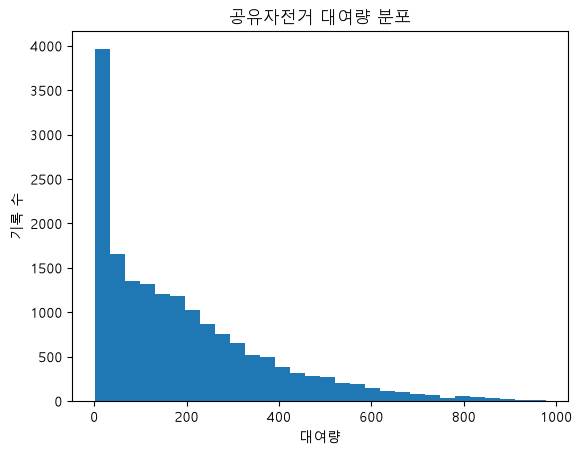

In [10]:
plt.hist(df["cnt"], bins=30)                   # 대여량을 30개 구간으로 나누어 히스토그램 그리기

plt.xlabel("대여량")                           # 가로축 이름
plt.ylabel("기록 수")                          # 세로축 이름
plt.title("공유자전거 대여량 분포")             # 그래프 제목
plt.show()                                    # 그래프 표시
#1시간 동안 자전거가 약 0~33대 대여된 기록이 약 4,000개 

In [11]:
# TODO 1-5. 시간대(hr)별 평균 대여량을 계산합니다.
hourly_mean = df.groupby("hr")["cnt"].mean()  # 시간대별로 기록을 묶어 평균 대여량 계산

print("시간대별 평균 대여량:\n", hourly_mean)    # 시간대와 계산된 평균 대여량 출력
# 자전거 대여량은 출퇴근 시간대(8시, 17~18시)에 높고 새벽에 가장 낮다.

시간대별 평균 대여량:
 hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64


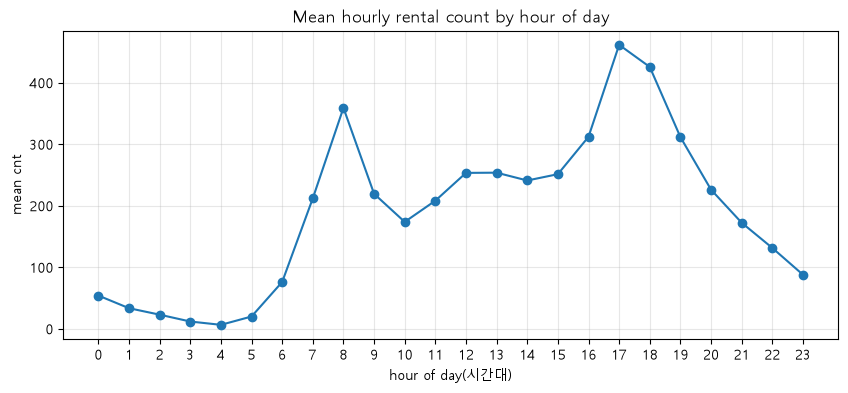

In [12]:
# [공통] 그래프 기본 설정
plt.figure(figsize=(10, 4)) # 그래프 크기 설정: 가로 10, 세로 4

# TODO 1-6. 시간대별 평균 대여량 선 그래프를 그립니다.
plt.plot(hourly_mean.index, hourly_mean.values, marker="o") # 시간대별 평균 대여량을 선과 점으로 표시

plt.xticks(range(0, 24))  # 가로축에 0시부터 23시까지 표시
plt.xlabel("hour of day(시간대)")
plt.ylabel("mean cnt")
plt.title("Mean hourly rental count by hour of day")
plt.grid(alpha=0.3)
plt.show() # 자전거 대여량은 출퇴근 시간대(8시, 17~18시)에 높고 새벽에 가장 낮다.

**[CP-01] 완료 기준:** 데이터 크기·결측값·중복 여부를 확인하고, `cnt` 분포와 시간대별 평균 대여량 그래프를 완성합니다.

**선택 심화:** 평일과 주말의 시간대별 대여량을 비교해 봅니다.

---
## ② 입력 특성 선택 및 상관관계 분석 — CP-02
**목표:** 날짜별 데이터 분할, 누수 확인, Train 상관관계 분석을 마치고 입력 특성을 결정합니다.

### ②-1. 시간 순서 분할 — 일부 공통 코드 + TODO

시간 순서로 분할하는 이유: 과거 기록으로 학습하고 이후 기록으로 평가해 미래 예측에 가까운 상황을 만든다.

- Train: 모델과 전처리 기준을 학습하는 데 사용한다.
- Validation: 같은 검증 기간에서 후보 모델과 설정을 비교하는 데 사용한다.
- Test: 모델과 설정을 확정한 뒤 마지막 평가에 사용한다.

`pd.to_datetime()`으로 날짜 문자열을 날짜형으로 바꾸고 `sort_values()`로 날짜와 시간 순으로 정렬한다. `unique()`로 중복 없는 날짜를 뽑아 앞에서부터 약 70%, 15%, 나머지로 나눈다. `isin()`으로 각 날짜 집합에 속한 행을 선택한다.

확인할 내용: Train, Validation, Test의 날짜 범위가 순서대로 이어지고 겹치지 않는지 확인한다. 같은 날짜는 한 집합에만 포함한다. 날짜별 기록 수가 다를 수 있어 행 비율은 정확히 70:15:15가 아닐 수 있다.

In [13]:
# [공통] 날짜 변환 및 시간 순서 정렬
df["dteday"] = pd.to_datetime(df["dteday"])          # 날짜 문자열을 날짜 자료형으로 변환
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)  # 날짜, 시간순 정렬 후 행 번호를 다시 매김

dates = np.sort(df["dteday"].unique())               # 중복 없는 날짜를 시간순으로 정렬
n_dates = len(dates)                                 # 전체 날짜의 개수

# TODO 2-1. 날짜 기준 Train 약 70%, Validation 약 15%, 나머지 Test로 분할합니다.
# 같은 날짜의 행은 반드시 같은 집합에 포함되어야 합니다.
# 힌트: int(), 날짜 배열 슬라이싱, .isin()
n_train = int(n_dates * 0.7)                         # 전체 날짜 중 약 70%를 Train에 할당
n_valid = int(n_dates * 0.15)                        # 전체 날짜 중 약 15%를 Validation에 할당

train_dates = dates[:n_train]                        # 처음부터 Train 날짜 수만큼 선택
valid_dates = dates[n_train:n_train + n_valid]       # Train 이후부터 Validation 날짜 수만큼 선택
test_dates = dates[n_train + n_valid:]               # 나머지 날짜를 Test로 선택

train_df = df[df["dteday"].isin(train_dates)].copy()  # Train 날짜에 해당하는 행만 선택
valid_df = df[df["dteday"].isin(valid_dates)].copy()  # Validation 날짜에 해당하는 행만 선택
test_df = df[df["dteday"].isin(test_dates)].copy()    # Test 날짜에 해당하는 행만 선택

In [14]:
# 세 데이터 집합을 차례로 확인
for name, part in [
    ("Train", train_df),          # name에는 "Train", part에는 train_df가 들어감
    ("Validation", valid_df),     # 다음 반복에서는 Validation 데이터 확인
    ("Test", test_df),            # 마지막으로 Test 데이터 확인
]:
    print(name, part.shape)       # 집합 이름과 (행 개수, 열 개수) 출력
    print(part["dteday"].min(), "~", part["dteday"].max())  # 가장 이른 날짜와 늦은 날짜 출력
    print()

Train (12139, 17)
2011-01-01 00:00:00 ~ 2012-05-25 00:00:00

Validation (2616, 17)
2012-05-26 00:00:00 ~ 2012-09-11 00:00:00

Test (2624, 17)
2012-09-12 00:00:00 ~ 2012-12-31 00:00:00



### ②-2. 데이터 누수 확인 — TODO

데이터 누수를 확인하는 이유: 예측 시점에 알 수 없는 정보를 입력하면 실제보다 성능이 좋아 보일 수 있으므로 사용 가능한 정보인지 판단한다.

`casual`은 비회원 대여량, `registered`는 회원 대여량, `cnt`는 총 대여량이다. `(casual + registered == cnt).all()`로 두 대여량의 합이 총 대여량과 같은지 모든 행에서 검사한다. 결과가 `True`이면 이 데이터의 모든 행에서 관계가 성립한다.

입력에서 제외하는 이유: 미래 시간대의 실제 회원·비회원 대여량은 대여가 끝나기 전에 알 수 없으므로 `casual`과 `registered`를 제외한다. 상관관계가 높아도 예측 시점에 사용할 수 있는지 먼저 확인한다.

In [85]:
# TODO 2-2. casual + registered == cnt가 모든 행에서 성립하는지 확인합니다.
same = (df["casual"] + df["registered"] == df["cnt"]).all()  # 모든 행이 같으면 True

print("데이터 관계 확인:", same)  # 모든 행에서 관계가 성립하는지 출력

# TODO (추가 확인). casual, registered, cnt의 상관관계를 비교해 봅니다.
correlation = df[["casual", "registered", "cnt"]].corr()  # 각 컬럼 쌍의 상관관계 계산

print("\n대여량 컬럼 간 상관관계:\n", correlation)  # 계산한 상관관계 표 출력

데이터 관계 확인: True

대여량 컬럼 간 상관관계:
               casual  registered       cnt
casual      1.000000    0.506618  0.694564
registered  0.506618    1.000000  0.972151
cnt         0.694564    0.972151  1.000000


### ②-3. 상관관계 분석 — TODO

상관관계를 분석하는 이유: 훈련 기간의 기온·체감온도·습도·풍속과 대여량이 함께 변하는 경향을 살펴보고 특성 선택에 참고한다.

`train_df[corr_cols].corr()`로 선택한 컬럼 쌍의 상관계수를 계산하고, `corr.round(3)`으로 소수점 셋째 자리까지 표시한다. 히트맵에서 빨간색은 양의 관계, 파란색은 음의 관계, 가운데에 가까운 색은 약한 선형 관계를 나타낸다.

결과 해석: `cnt`와 날씨 특성 간 관계, `temp`와 `atemp`가 서로 비슷하게 움직이는 정도를 확인한다. 상관관계는 인과관계를 증명하지 않음. 상관계수가 낮아도 비선형 관계가 있을 수 있다.

In [16]:
# [공통] 분석에 사용할 컬럼
corr_cols = ["temp", "atemp", "hum", "windspeed", "cnt"]

# TODO 2-3. Train 데이터로만 상관계수를 계산합니다.
corr = train_df[corr_cols].corr()  # Train에서 선택한 컬럼들의 상관계수 계산
display(corr.round(3))

,temp,atemp,hum,windspeed,cnt
temp,1.000,0.992,-0.016,-0.015,0.398
atemp,0.992,1.000,-0.000,-0.058,0.398
hum,-0.016,-0.000,1.000,-0.297,-0.301
windspeed,-0.015,-0.058,-0.297,1.000,0.094
cnt,0.398,0.398,-0.301,0.094,1.000


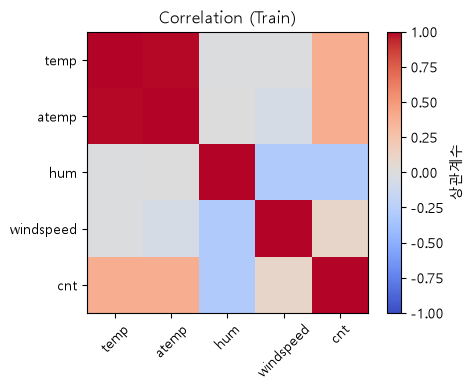

In [17]:
# [공통] 상관관계 시각화 기본 구조
plt.figure(figsize=(5, 4))

# TODO 2-4. 상관관계 행렬을 히트맵으로 시각화합니다.
# 힌트: plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
#       plt.colorbar(label="correlation")
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)  # 상관계수를 -1~1 범위의 색으로 표시
plt.colorbar(label="상관계수")                      # 색이 어떤 상관계수를 뜻하는지 표시

plt.xticks(range(len(corr_cols)), corr_cols, rotation=45)
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Correlation (Train)")
plt.tight_layout()
plt.show()
# Train에서 기온·체감온도는 대여량과 양의 상관관계
# 습도는 음의 상관관계, 풍속은 약한 선형 상관관계
# 기온과 체감온도의 상관계수는 0.992로 매우 높았다.
# 상관관계는 인과관계를 뜻하지 않으며, 낮은 상관계수만으로 특성을 제외하지 않는다.

### ②-4. 입력 특성 선택 — TODO (핵심 의사결정 ①)

입력 특성을 선택하는 이유: 모델에 알려줄 정보와 모델이 맞혀야 할 정답을 구분한다. 사용하거나 제외한 이유를 기록해 이후 모델 결과를 설명하는 데 사용한다.

`FEATURES`에는 입력 컬럼 이름을 저장하고 `TARGET`에는 예측 대상인 총 대여량 `cnt`를 지정한다. `casual`과 `registered`는 예측 시점에 알 수 없는 실제 대여량이고 `instant`는 행 식별자이므로 제외한다. `dteday`는 분할에 사용하고, 입력에는 연도·월·요일 등의 컬럼을 사용한다.

`X_train`, `X_valid`, `X_test`에는 입력 컬럼을 저장하고, `y_train`, `y_valid`, `y_test`에는 정답을 저장한다. `shape`로 각 집합에서 입력과 정답의 행 수가 같은지 확인한다.

기온과 체감온도는 둘 다 사용한다. 두 특성의 상관관계가 높으므로 이후 실험에서 선택의 영향을 비교할 수 있다. 실제 예측 시 날씨 입력은 해당 시간의 예보 등으로 확보할 수 있다고 가정한다.

In [18]:
# TODO 2-5. 모델에 사용할 입력 컬럼을 선택합니다.
FEATURES = [
    "season",      # 계절
    "yr",          # 연도
    "mnth",        # 월
    "hr",          # 시간대
    "holiday",     # 공휴일 여부
    "weekday",     # 요일
    "workingday",  # 근무일 여부
    "weathersit",  # 날씨 상태
    "temp",        # 기온
    "atemp",       # 체감온도
    "hum",         # 습도
    "windspeed",   # 풍속
]
TARGET = "cnt"  # 예측할 정답: 시간당 총 대여량

print("사용할 특성:", FEATURES)  # 선택한 입력 특성 출력

사용할 특성: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


In [19]:
# [공통] 입력 X와 정답 y 분리
X_train = train_df[FEATURES].copy()
X_valid = valid_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()

y_train = train_df[TARGET]
y_valid = valid_df[TARGET]
y_test = test_df[TARGET]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (12139, 12) (12139,)
Validation: (2616, 12) (2616,)
Test: (2624, 12) (2624,)


**[CP-02] 완료 기준 :** 분할한 데이터의 기간·크기를 확인하고, 누수 검증 결과·Train 상관관계 표·선택한 `FEATURES`를 설명할 수 있습니다.

---
## ③ 특성공학 및 데이터 전처리 — CP-03
**목표:** 출퇴근 시간 특성을 생성하고, 인코딩·표준화·전처리 결합을 구현합니다.

### ③-1. 출퇴근 특성 생성 — TODO

출퇴근 특성을 만드는 이유: `hr`(시간대)과 `workingday`(근무일 여부)를 조합해 `is_commute_hour`라는 새 입력 특성을 만든다. 기존 데이터에서 새 특성을 만드는 작업을 특성공학이라고 한다.

- 근무일(`workingday == 1`)이면서 출퇴근 시간 목록에 있으면 `1`, 그 외에는 `0`으로 표시한다.
- 예: 근무일 8시는 `1`, 휴일 8시와 근무일 14시는 `0`이다.
- `isin()`은 시간 목록에 값이 있는지 확인하고, `&`는 두 조건이 모두 참인지 확인한다. `astype(int)`는 `True`와 `False`를 `1`과 `0`으로 바꾼다.
- 새 특성이 모델 성능을 높이는지는 이후 실험으로 확인한다.

In [89]:
# [공통] 실습에서 사용할 출퇴근 시간 가정
COMMUTE_HOURS = [7, 8, 9, 17, 18, 19]


def add_commute_feature(X):
    """기존 hr와 workingday로 is_commute_hour 특성을 추가합니다."""
    X = X.copy()

    # TODO 3-1. workingday == 1이면서 hr이 COMMUTE_HOURS에 있으면 1, 아니면 0
    # 근무일이고 출퇴근 시간대이면 1, 그 외에는 0을 새 컬럼에 저장
    X["is_commute_hour"] = (
        (X["workingday"] == 1) &               # 근무일인지 확인
        (X["hr"].isin(COMMUTE_HOURS))           # 출퇴근 시간 목록에 있는지 확인
    ).astype(int)                               # True는 1, False는 0으로 변환

    return X  # 새 컬럼이 추가된 데이터 반환


# [공통] 모든 집합에 같은 특성공학 함수 적용
X_train = add_commute_feature(X_train)
X_valid = add_commute_feature(X_valid)
X_test = add_commute_feature(X_test)

In [90]:
# [공통] 간단 검증 — 기대 결과는 [1, 0, 0, 1]
check = pd.DataFrame({"hr": [8, 8, 14, 18], "workingday": [1, 0, 1, 1]})
print(add_commute_feature(check))

   hr  workingday  is_commute_hour
0   8           1                1
1   8           0                0
2  14           1                0
3  18           1                1


### ③-2. 특성 유형 구분 및 ColumnTransformer — TODO

특성을 나누는 이유: 숫자의 의미에 따라 알맞은 전처리를 적용하기 위해 세 목록으로 구분한다.

- 범주형: `season`, `weekday`, `hr`처럼 종류 또는 시간대를 나타내는 값이다. 이번 실습에서는 각 범주를 원-핫 인코딩한다.
- 수치형: `temp`, `hum`처럼 크기를 다루는 값이다. Train의 평균과 표준편차를 기준으로 표준화한다.
- 이진형: `workingday`, `is_commute_hour`처럼 0과 1로 구분하는 값이다. 이 데이터의 `yr`도 0과 1로 구분해 여기에 포함한다.

`assert`로 특성의 중복 여부와 `X_train` 컬럼의 누락 여부를 확인한다.

In [92]:
# TODO 3-2. 선택한 입력 특성을 세 유형으로 구분합니다.
# 범주형(One-Hot 인코딩), 수치형(StandardScaler), 이진형(그대로 사용)
# ②교시 FEATURES와 새로 만든 is_commute_hour가 모두 포함되어야 합니다.
categorical_features = ["season", "mnth", "hr", "weekday", "weathersit"]  # 범주형
numeric_features = ["temp", "atemp", "hum", "windspeed"]                 # 수치형
binary_features = ["yr", "holiday", "workingday", "is_commute_hour"]     # 이진형

# [공통] 중복/누락 없는지 확인
all_features = categorical_features + numeric_features + binary_features
assert len(all_features) == len(set(all_features)), "특성 목록이 중복됩니다."
assert set(all_features) == set(X_train.columns), "분류되지 않은 컬럼이 있습니다."

print("범주형:", categorical_features)
print("수치형:", numeric_features)
print("이진형:", binary_features)

범주형: ['season', 'mnth', 'hr', 'weekday', 'weathersit']
수치형: ['temp', 'atemp', 'hum', 'windspeed']
이진형: ['yr', 'holiday', 'workingday', 'is_commute_hour']


In [94]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer


def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "범주형",  # 이 변환에 붙이는 이름
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),  # 범주를 0과 1로 변환
                categorical_features,  # 변환할 범주형 컬럼 목록
            ),
            (
                "수치형",  # 이 변환에 붙이는 이름
                StandardScaler(),  # 수치형 컬럼을 표준화
                numeric_features,  # 변환할 수치형 컬럼 목록
            ),
            (
                "이진형",  # 이 변환에 붙이는 이름
                "passthrough",  # 값을 변환하지 않고 그대로 사용
                binary_features,  # 그대로 통과시킬 이진형 컬럼 목록
            ),
        ]
    )

preprocessor = make_preprocessor()  # 전처리 객체 생성

# Train으로 변환 기준을 학습하고 Train을 변환
Xt_train = preprocessor.fit_transform(X_train)

# Train에서 학습한 기준을 그대로 Validation에 적용
Xt_valid = preprocessor.transform(X_valid)

print("변환 전 Train:", X_train.shape, "→ 변환 후:", Xt_train.shape)
print()
print("변환 전 Valid:", X_valid.shape, "→ 변환 후:", Xt_valid.shape)

변환 전 Train: (12139, 13) → 변환 후: (12139, 59)

변환 전 Valid: (2616, 13) → 변환 후: (2616, 59)


### ③-3. 전처리 결과 확인 — 공통 코드

전처리를 적용하는 이유: 특성 유형에 맞게 값을 변환하고, Train에서 학습한 기준을 Validation에 적용한다.

`ColumnTransformer`로 범주형에 `OneHotEncoder`, 수치형에 `StandardScaler`, 이진형에 `passthrough`를 적용한다. 예를 들어 시간대 8시는 `hr_8`이 1인 형태로 표현한다.

`fit_transform(X_train)`으로 Train의 범주와 표준화 기준을 학습하고 Train을 변환한다. `transform(X_valid)`에는 Train에서 배운 기준을 그대로 적용해 평가 데이터의 정보가 전처리 기준에 섞이지 않도록 한다.

결과 확인: `shape`는 (행 수, 열 수)를 나타낸다. 행 수는 유지되고 원-핫 인코딩으로 열 수는 늘어날 수 있다. 변환된 Train과 Validation의 열 수가 같은지 확인한다.

In [97]:
# Train에서만 전처리 기준을 학습합니다.
Xt_train = preprocessor.fit_transform(X_train)
Xt_valid = preprocessor.transform(X_valid)

print("변환 전 Train:", X_train.shape, "→ 변환 후:", Xt_train.shape)
print()
print("변환 전 Valid:", X_valid.shape, "→ 변환 후:", Xt_valid.shape)

변환 전 Train: (12139, 13) → 변환 후: (12139, 59)

변환 전 Valid: (2616, 13) → 변환 후: (2616, 59)


**[CP-03] 완료 기준:** `is_commute_hour`를 생성하고 `make_preprocessor()`가 정상 실행되며, Train/Validation 변환 결과를 출력합니다.

**선택 심화:** 시간대의 주기성을 반영하는 특성을 추가해 봅니다.

---
## ④ 기준 모델 및 선형회귀 — CP-04
**목표:** DummyRegressor·LinearRegression을 학습하고 MAE·RMSE·R² 공통 평가 함수를 구현합니다.

### ④-1. 모델 구성과 학습 — TODO


모델을 학습하는 이유: 시간·날씨 등의 입력 정보로 시간당 대여량을 예측하고, 단순한 예측 기준과 비교한다.

- TODO 4-1의 `DummyRegressor(strategy="mean")`는 Train 정답 대여량의 평균을 학습하고, 시간이나 날씨와 관계없이 같은 값을 예측한다. 다른 모델이 넘어야 할 기준 모델로 사용한다.
- TODO 4-2의 `LinearRegression`은 입력 특성마다 학습한 계수를 곱해 더한 뒤 절편을 더하는 방식으로 대여량을 예측한다. 다른 입력이 같을 때 각 입력의 변화가 예측값에 어떻게 반영될지 학습한다.
- `Pipeline`은 CP-03의 전처리와 모델을 순서대로 연결한다. 모델마다 별도의 전처리 객체를 만들며, `fit(X_train, y_train)`으로 Train의 입력과 실제 대여량을 사용해 학습한다.
- `학습 완료`는 두 학습 명령이 끝났다는 뜻이다. 어느 모델이 더 정확한지는 다음 평가 결과로 확인한다.

생각할 점: 기준 모델은 모든 시간에 같은 값을 예측하므로, 새벽과 출퇴근 시간처럼 수요가 다른 상황을 얼마나 잘 맞힐 수 있을지 확인한다. 선형 회귀가 이 기준보다 개선됐는지는 같은 Validation 데이터에서 비교한다.

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# TODO 4-1. 전처리와 기준 모델을 연결한다.
dummy_model = Pipeline([
    ("preprocessor", make_preprocessor()),       # CP-03에서 만든 전처리
    ("model", DummyRegressor(strategy="mean")),  # 훈련 대여량의 평균을 예측
])

# TODO 4-2. 전처리와 선형 회귀 모델을 연결한다.
linear_model = Pipeline([
    ("preprocessor", make_preprocessor()),  # CP-03에서 만든 전처리
    ("model", LinearRegression()),         # 선형 회귀 모델
])

# [공통] 모델 학습
dummy_model.fit(X_train, y_train)
linear_model.fit(X_train, y_train)
print("학습 완료")

학습 완료


### ④-2. 평가 함수 — TODO / 결과 정리 함수 — 공통


평가 함수를 만드는 이유: 각 모델이 예측한 대여량과 실제 대여량의 차이를 같은 기준으로 계산해 비교한다.

- `model.predict(X)`는 입력 정보로 대여량을 예측한다. 예측값은 `pred`, 실제 대여량은 `y`다.
- MAE는 절대 오차의 평균이다. 예를 들어 MAE가 50이면 시간대당 실제 대여량과 평균적으로 50대 차이 난다는 뜻이다. 낮을수록 좋다.
- RMSE는 오차를 제곱해 큰 오차를 더 크게 반영한 뒤 제곱근을 구한다. 단위는 대여량과 같은 대이며 낮을수록 좋다.
- R²는 평가 대상 데이터의 실제 대여량 평균으로 예측했을 때와 모델의 제곱오차를 비교한다. 1은 완벽한 예측, 0은 평균 예측과 같은 제곱오차, 음수는 평균 예측보다 큰 제곱오차를 뜻한다.
- 기준 모델이 새 데이터를 예측할 때 사용하는 평균은 Train 정답 평균이다. R² 계산에 사용하는 비교 기준은 해당 평가 데이터 정답의 평균이므로, 기준 모델의 Validation R²가 반드시 0인 것은 아니다.

`evaluate_regression()`은 한 모델의 세 지표를 계산한다. `summarize()`는 같은 모델을 Train과 Validation에서 각각 평가해 한 행으로 정리한다. 이 셀은 함수를 정의하므로 실행해도 별도 표가 나오지 않는다.

TODO 4-4 비교표를 만드는 이유: `results`에 두 모델의 평가 결과를 모아 DataFrame으로 표시하고, 같은 Validation 기간에서 예측 성능을 비교한다. Validation MAE를 우선 보고 RMSE, R², Train과 Validation의 차이도 살펴본다. MAE와 RMSE는 낮을수록, R²는 높을수록 좋다.

결과 해석: 현재 저장된 표에서 기준 모델의 Validation MAE는 194.109대, 선형 회귀의 Validation MAE는 99.854대다. 이 Validation 기간에서는 선형 회귀의 평균 절대 오차가 더 작다. 이는 모델이 모든 시간대에 잘 맞는다는 뜻은 아니며, Train과 Validation의 기간·계절이 달라 점수 차이를 해석할 때 그 차이도 고려한다. 시간대별 오류는 CP-07에서 확인하고 Test는 최종 선택 이후 평가에 사용한다.

In [35]:
from sklearn.metrics import (
    mean_absolute_error,       # MAE 계산
    root_mean_squared_error,   # RMSE 계산
    r2_score,                  # R² 계산
)


def evaluate_regression(model, X, y):
    """모델의 MAE, RMSE, R²를 계산해 딕셔너리로 반환한다."""

    pred = model.predict(X)  # 입력 데이터 X로 대여량 예측

    return {
        "MAE": mean_absolute_error(y, pred),        # 실제값과 예측값의 평균 절대 오차
        "RMSE": root_mean_squared_error(y, pred),   # 큰 오차에 더 큰 비중을 두는 지표
        "R2": r2_score(y, pred),                   # 평균 예측과 비교한 결정계수
    }


def summarize(name, model):
    """하나의 모델에 대한 Train·Validation 평가 결과를 정리한다."""

    tr = evaluate_regression(model, X_train, y_train)  # Train 성능 계산
    va = evaluate_regression(model, X_valid, y_valid)  # Validation 성능 계산

    return {
        "Model": name,             # 모델 이름
        "Train MAE": tr["MAE"],    # 훈련 데이터의 MAE
        "Train RMSE": tr["RMSE"],  # 훈련 데이터의 RMSE
        "Train R2": tr["R2"],      # 훈련 데이터의 R²
        "Valid MAE": va["MAE"],    # 검증 데이터의 MAE
        "Valid RMSE": va["RMSE"],  # 검증 데이터의 RMSE
        "Valid R2": va["R2"],      # 검증 데이터의 R²
    }

In [36]:
# [공통] 이후 교시에서 결과를 누적할 리스트
results = []
results.append(summarize("DummyRegressor", dummy_model))
results.append(summarize("LinearRegression", linear_model))

# TODO 4-4. 두 모델의 성능을 DataFrame으로 비교합니다.
results_df = pd.DataFrame(results).round(3)  # 결과를 표로 만들고 소수점 셋째 자리까지 표시
display(results_df)                         # 비교표 출력

,Model,Train MAE,Train RMSE,Train R2,Valid MAE,Valid RMSE,Valid R2
0,DummyRegressor,119.572,152.40,0.000,194.109,253.892,-0.296
1,LinearRegression,55.334,73.41,0.768,99.854,124.008,0.691


**[CP-04] 완료 기준:** 두 모델을 학습하고 공통 평가 함수로 Train·Validation 성능을 표로 비교합니다.

### 선형 회귀의 적합도 해석

과대적합 가능성: 선형 회귀의 Train MAE는 55.334대, Validation MAE는 99.854대로 검증 오차가 더 크다. 훈련 데이터에 더 잘 맞는 경향이 있어 과대적합을 의심할 수 있다. 다만 두 기간의 계절과 수요 패턴이 다르므로, 이 차이만으로 과대적합을 확정할 수 없다.

과소적합 가능성: 선형 회귀의 Train MAE 55.334대는 기준 모델의 119.572대보다 낮아 훈련 데이터의 관계를 어느 정도 학습했다. 다만 이후 CP-05에서 비교한 깊이 12 결정 트리의 Train MAE는 32.297대로 더 낮았다. 선형 회귀가 훈련 데이터의 일부 관계를 충분히 표현하지 못했을 가능성을 살펴볼 근거다. 더 복잡한 트리가 훈련 기록에 더 세밀하게 맞춰졌을 수도 있으므로, 이 결과만으로 과소적합을 확정할 수 없다.

추가 판단: 깊이 12 트리의 Validation MAE는 107.288대로 선형 회귀의 99.854대보다 높다. 훈련 오차가 낮다는 이유만으로 트리가 더 좋은 모델이라고 판단하지 않는다. 같은 검증 기간에서 비교하고, 시간대·계절별 오류와 여러 시간순 검증 구간을 살펴본다. Test는 최종 모델을 확정한 뒤 평가에 사용한다.


---
## ⑤ Decision Tree 모델 개선 — CP-05
**목표:** `max_depth`를 바꿔 학습·검증 MAE를 비교하고 그래프로 표현합니다.

### ⑤-1. 깊이별 모델 학습 — TODO


결정 트리를 실험하는 이유: CP-04의 선형 회귀와 다른 방식으로 대여량 패턴을 학습하고, 조건에 따라 나누는 모델이 예측에 도움이 되는지 확인한다.

결정 트리는 Train 데이터를 조건에 따라 나누고, 각 기록이 도착한 마지막 그룹의 훈련 대여량 평균을 예측값으로 사용한다. 예를 들어 근무일 여부로 나눈 뒤 시간대에 따라 다시 나눌 수 있다. 실제 분할 조건은 Train 데이터를 통해 학습한다.

트리 깊이를 바꾸는 이유: `max_depth`는 조건을 몇 단계까지 나눌지 제한한다. 얕은 트리는 중요한 패턴을 충분히 구분하지 못할 수 있고, 깊은 트리는 훈련 기록에 지나치게 맞춰질 수 있다. 이 실험에서는 깊이 3, 6, 12, 15, 20과 깊이 제한 없는 설정을 비교한다.

- TODO 5-1: 각 깊이에서 CP-03의 전처리와 `DecisionTreeRegressor`를 `Pipeline`으로 연결한다. `random_state`는 같은 조건에서 결과를 재현하는 데 사용한다.
- TODO 5-2: 동일한 Train 데이터로 각 모델을 학습한다.
- TODO 5-3: CP-04의 `summarize()`를 사용해 Train과 Validation 성능을 같은 지표로 계산하고, 모델과 결과를 보관한다.

비교할 내용: `Train MAE`와 `Valid MAE`를 깊이별로 확인한다. MAE는 실제 대여량과 예측 대여량의 절대 차이를 평균 낸 값이며, 낮을수록 평균 오차가 작다. 모델들은 같은 Validation 기간에서 비교한다.

실행 시 주의: 이 셀은 결과를 `results`에도 추가하므로 반복 실행하면 전체 결과에 같은 실험이 중복될 수 있다. 다시 실험할 때는 CP-04의 `results = []`부터 결과 목록을 다시 구성한다.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# [공통] 실험 설정 및 저장 구조
depths = [3, 6, 12, 15, 20, None]  # 결정 트리의 최대 깊이 후보, 15, 20, None은 과적합 여부 확인용
tree_models = {}
tree_results = []

# TODO 5-1~5-3. 각 깊이별 Pipeline 생성·학습·평가 결과 수집
for d in depths:
    # TODO 5-1. 전처리 + DecisionTreeRegressor(max_depth=d, random_state=42)
    model = Pipeline([
        ("preprocessor", make_preprocessor()),  # CP-03에서 만든 전처리
        ("model", DecisionTreeRegressor(
            max_depth=d,      # 이번 반복에서 사용할 트리 깊이
            random_state=42,  # 같은 조건에서 결과를 재현하기 위한 설정
        )),
    ])

    # TODO 5-2. 모델 학습
    model.fit(X_train, y_train)

    # [공통] 학습한 모델 보관
    tree_models[d] = model

    # TODO 5-3. summarize()로 성능 결과 수집
    row = summarize(f"DecisionTree_depth_{d}", model)
    tree_results.append(row)  # 결정 트리끼리 비교할 결과에 추가
    results.append(row)       # 이후 전체 모델 비교에 사용할 결과에 추가

# [공통] 결과 정리
tree_df = pd.DataFrame(tree_results)
tree_df["max_depth"] = depths
display(tree_df.round(3))
# 추가한 여섯 설정 중 깊이 제한이 없는 트리의 Validation MAE가 가장 낮았다.
# 선형 회귀와의 비교 및 자세한 해석은 아래 비교표에서 확인한다.

,Model,Train MAE,Train RMSE,Train R2,Valid MAE,Valid RMSE,Valid R2,max_depth
0,DecisionTree_depth_3,82.785,108.741,0.491,158.976,194.181,0.242,3.0
1,DecisionTree_depth_6,62.340,84.667,0.691,120.455,160.465,0.482,6.0
2,DecisionTree_depth_12,32.297,52.673,0.881,107.288,161.604,0.475,12.0
3,DecisionTree_depth_15,21.628,40.712,0.929,101.432,157.598,0.501,15.0
4,DecisionTree_depth_20,9.610,23.392,0.976,110.955,174.651,0.387,20.0
5,DecisionTree_depth_None,0.012,0.551,1.000,99.455,153.082,0.529,NaN


In [39]:
# 선형 회귀와 깊이별 결정 트리의 Train·Validation 성능을 비교한다.
# Validation MAE 순서로 정렬하고 RMSE와 R²도 함께 확인한다.

# 선형 회귀의 Train·Validation 성능을 한 행으로 정리
linear_row = pd.DataFrame([
    summarize("LinearRegression", linear_model)
])

linear_row["max_depth"] = "해당 없음"  # 선형 회귀에는 트리 깊이가 없음

# 결정 트리 결과를 복사하고, 깊이 제한이 없는 설정을 알아보기 쉽게 표시
tree_comparison = tree_df.copy()
tree_comparison["max_depth"] = tree_comparison["max_depth"].astype(object)
tree_comparison["max_depth"] = tree_comparison["max_depth"].where(
    tree_comparison["max_depth"].notna(),
    "제한 없음",
)

# 선형 회귀와 결정 트리 결과를 하나의 표로 합치기
comparison_df = pd.concat(
    [linear_row, tree_comparison],
    ignore_index=True,
)

# Validation MAE가 낮은 모델부터 정렬
comparison_df = comparison_df.sort_values(
    by="Valid MAE",
).reset_index(drop=True)

print("선형 회귀와 결정 트리 성능 비교")
display(comparison_df.round(3))

선형 회귀와 결정 트리 성능 비교


,Model,Train MAE,Train RMSE,Train R2,Valid MAE,Valid RMSE,Valid R2,max_depth
0,DecisionTree_depth_None,0.012,0.551,1.000,99.455,153.082,0.529,제한 없음
1,LinearRegression,55.334,73.410,0.768,99.854,124.008,0.691,해당 없음
2,DecisionTree_depth_15,21.628,40.712,0.929,101.432,157.598,0.501,15.0
3,DecisionTree_depth_12,32.297,52.673,0.881,107.288,161.604,0.475,12.0
4,DecisionTree_depth_20,9.610,23.392,0.976,110.955,174.651,0.387,20.0
5,DecisionTree_depth_6,62.340,84.667,0.691,120.455,160.465,0.482,6.0
6,DecisionTree_depth_3,82.785,108.741,0.491,158.976,194.181,0.242,3.0


### 선형 회귀와 결정 트리 비교 결과

깊이 제한이 없는 결정 트리의 Validation MAE는 99.455대로 선형 회귀의 99.854대보다 0.399대 낮았다. 이번 검증 기간에서 결정 트리의 평균 절대 오차가 근소하게 작았다.

Validation RMSE는 선형 회귀가 124.008대로 결정 트리의 153.082대보다 낮았다. 큰 오차에 더 비중을 둔 지표에서는 선형 회귀의 결과가 더 좋았다. 어떤 시간대에 큰 오류가 발생했는지는 이 표만으로 확인할 수 없으므로 CP-07에서 추가로 분석한다.

깊이 제한이 없는 결정 트리의 Train MAE는 0.012대로 거의 0인 반면 Validation MAE는 99.455대였다. 훈련 기록과 검증 기간의 오차 차이가 커서 과대적합 가능성을 살펴볼 필요가 있다. 다만 두 데이터의 기간과 계절 구성이 다르므로 차이의 원인을 과대적합으로 확정하지 않는다.

현재 판단: 두 모델의 Validation MAE 차이가 작고 선형 회귀의 RMSE가 더 낮으므로, 큰 예측 오차를 중요하게 본다면 선형 회귀를 우선 후보로 고려할 수 있다. 최종 선택 전에는 시간대별 오류와 다른 시간순 검증 기간의 성능을 확인한다. Test는 모델을 최종 선택한 뒤 평가에 사용한다.


### ⑤-2. 모델 복잡도와 오차 시각화 — TODO


그래프를 그리는 이유: 깊이가 달라질 때 Train과 Validation의 오차가 각각 어떻게 변하는지 한눈에 비교한다.

가로축은 트리 깊이 `max_depth`, 세로축은 MAE다. Train MAE와 Validation MAE를 각각 선으로 표시하며, 각 점은 같은 깊이의 모델을 서로 다른 데이터에서 평가한 결과다.

결과를 해석하는 기준:
- 두 오차가 모두 크다면 모델이 훈련 데이터의 관계도 충분히 표현하지 못했을 가능성을 살펴본다.
- 깊이가 늘면서 Train 오차는 줄고 Validation 오차는 커진다면 과대적합 가능성을 살펴본다.
- Validation MAE가 가장 작은 깊이를 후보로 삼되, Train과 Validation의 차이도 함께 확인한다.

주의할 점: Train과 Validation은 기간과 계절 구성이 다르므로 두 점수의 차이를 과대적합만으로 단정하지 않는다. 여러 모델을 비교할 때는 같은 Validation 기간과 같은 MAE 기준을 사용하며, Test는 모델을 최종 선택한 뒤 평가에 사용한다.

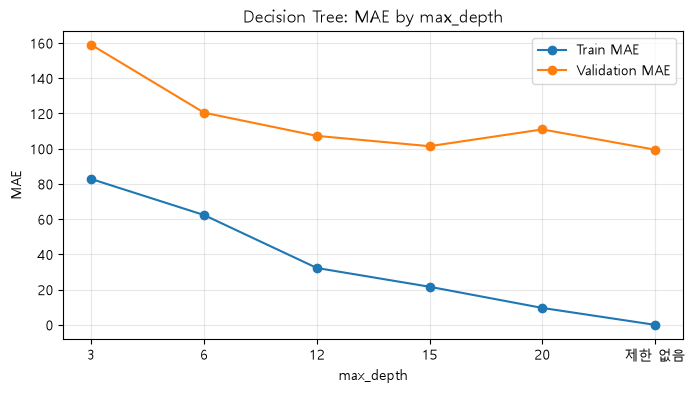

In [42]:
positions = list(range(len(depths)))

# None은 숫자 깊이가 아니므로 "제한 없음"으로 표시한다.
depth_labels = [
    str(depth) if depth is not None else "제한 없음"
    for depth in depths
]

# TODO 5-4. 깊이별 Train MAE와 Validation MAE를 각각 선 그래프로 표시합니다.
# # 실험 설정마다 그래프의 가로 위치를 하나씩 만든다.

# 그래프 크기 설정
plt.figure(figsize=(8, 4))

# 깊이별 Train MAE를 선과 점으로 표시한다.
plt.plot(
    positions,
    tree_df["Train MAE"],
    marker="o",
    label="Train MAE",
)

# 깊이별 Validation MAE를 선과 점으로 표시한다.
plt.plot(
    positions,
    tree_df["Valid MAE"],
    marker="o",
    label="Validation MAE",
)

plt.xticks(positions, depth_labels)              # 각 위치에 깊이 설정 표시
plt.xlabel("max_depth")                          # 가로축 이름
plt.ylabel("MAE")                               # 세로축 이름
plt.title("Decision Tree: MAE by max_depth")       # 그래프 제목
plt.legend()                                   # 선이 무엇을 뜻하는지 표시
plt.grid(alpha=0.3)                             # 연한 격자 표시
plt.show()                                     # 그래프 출력

**[CP-05]완료 기준:** 깊이 3·6·12의 성능표와 Train·Validation MAE 그래프를 완성합니다.

**선택 심화:** `min_samples_leaf` 설정을 추가로 실험합니다.

---
## ⑥ Random Forest 및 모델 통합 비교 — CP-06
**목표:** Random Forest 두 설정을 실험하고 네 종류 모델의 성능을 하나의 표로 비교합니다.

### ⑥-1. Random Forest 실험 — TODO

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# [공통] 비교할 두 설정
rf_configs = {
    "A": {"n_estimators": 50, "max_depth": 10},
    "B": {"n_estimators": 100, "max_depth": 15},
}
rf_models = {}

# TODO 6-1~6-2. 두 설정의 Random Forest Pipeline 학습 및 성능 수집
for key, params in rf_configs.items():
    # TODO: Pipeline 구성 (RandomForestRegressor(**params, random_state=42, n_jobs=-1))
    model = ...

    # TODO: 모델 학습
    ...

    # [공통] 학습한 모델 보관
    rf_models[key] = model

    # TODO: summarize()로 결과를 results에 추가합니다.
    ...

### ⑥-2. 전체 성능표 비교 — TODO

In [ ]:
# [공통] 지금까지 누적한 모델 결과
results_df = pd.DataFrame(results)

# TODO 6-3. Validation MAE가 낮은 순서로 정렬하고 인덱스를 정리합니다.
results_df = ...

# TODO 6-4. Validation MAE - Train MAE를 계산합니다.
results_df["Gap (Valid-Train MAE)"] = ...

display(results_df.round(3))

**[CP-06]완료 기준:** Dummy·Linear·Decision Tree·Random Forest 결과를 같은 Validation MAE 기준으로 비교합니다.

**선택 심화:** 추가 파라미터 탐색이나 시간 순서 교차검증을 시도합니다.

---
## ⑦ 오류 분석 및 최종 모델 선택 — CP-07
**목표:** 두 후보 모델의 예측 오차를 분석하고, 근거를 기록하여 최종 모델을 결정합니다.

### ⑦-1. 후보 모델과 잔차 — TODO

In [ ]:
# TODO 7-1. results_df를 검토하여 오류 분석할 후보 모델 2개를 선택합니다.
# tree_models, rf_models 또는 앞서 학습한 모델 객체를 활용합니다.
candidates = {
    # "후보 이름": 학습된 모델 객체
}

# [공통] 실제값과 시간대 DataFrame
pred_df = pd.DataFrame({
    "hr": X_valid["hr"].values,
    "actual": y_valid.values,
})

# TODO 7-2. 각 모델의 Validation 예측값과 잔차를 계산합니다.
for name, model in candidates.items():
    pred_df[f"pred_{name}"] = ...
    pred_df[f"resid_{name}"] = ...

display(pred_df.head())

### ⑦-2. 실제값과 예측값 시각화 — TODO

In [ ]:
# [공통] 두 후보 모델을 나란히 비교합니다.
assert len(candidates) == 2, "오류 분석 후보를 2개 선택하세요."
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
lim = pred_df["actual"].max() * 1.05

for ax, name in zip(axes, candidates):
    # TODO 7-3. 실제값(x)·예측값(y) 산점도와 y=x 기준선을 작성합니다.
    # 힌트: ax.scatter(), ax.plot()
    ...

    # [공통] 축 및 제목
    ax.set_xlabel("actual cnt")
    ax.set_ylabel("predicted cnt")
    ax.set_title(name)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)

plt.tight_layout()
plt.show()

### ⑦-3. 시간대별 MAE — TODO

In [ ]:
# [공통] 시간대별 오류 DataFrame
hourly_mae = pd.DataFrame(index=range(24))
hourly_mae.index.name = "hr"

for name in candidates:
    # TODO 7-4. 모델별 절대오차와 시간대별 평균 절대오차를 계산합니다.
    abs_err = ...
    hourly_mae[name] = ...

display(hourly_mae.round(1))

In [ ]:
# TODO 7-5. 후보 모델들의 시간대별 MAE를 막대그래프로 표현합니다.
# 힌트: plt.bar(), hourly_mae
...

### ⑦-4. 최종 모델 선택 — 기록

In [ ]:
# **TODO 7-6:** results_df의 Validation MAE, Train·Validation 성능 차이, 예측 오류 분석 결과를 비교하여 최종 모델과 설정을 선택합니다.
# 선택한 모델과 그 근거는 adr.md의 의사결정 ②에 기록합니다.
# 선택한 모델과 설정은 ⑧교시의 최종 학습에 사용합니다.

**[CP-07] 완료 기준:** 잔차와 시간대별 MAE 분석을 완료하고 최종 모델 선택 이유를 설명합니다.

**선택 심화:** Permutation Importance로 입력 특성의 기여도를 분석합니다 (필수 아님).

In [ ]:
# [선택 심화] 특성 중요도
# TODO (선택): sklearn.inspection.permutation_importance 를 사용해
# Validation 데이터에서 각 입력 특성을 섞었을 때 MAE가 얼마나 변하는지 분석합니다.
# 이 셀을 실행하지 않아도 ⑧교시 진행에 영향이 없습니다.

---
## ⑧ 최종 모델 완성 및 예측 — CP-08
**목표:** 선택한 모델을 재학습하고 Test 평가, 모델 저장·재로딩, 입력 한 건 예측까지 구현합니다.

### ⑧-1. 최종 모델 재학습 — TODO

In [ ]:
import joblib
from pathlib import Path

# [공통] Train과 Validation 데이터 결합
X_trainval = pd.concat([X_train, X_valid])
y_trainval = pd.concat([y_train, y_valid])

# TODO 8-1. ⑦에서 선택한 모델과 하이퍼파라미터로 새 estimator를 생성합니다.
# 예: 앞서 사용한 회귀 모델 클래스와 선택한 설정을 사용합니다.
final_estimator = ...

# [공통] 최종 Pipeline은 전처리를 포함해야 합니다.
final_model = Pipeline([
    ("prep", make_preprocessor()),
    ("model", final_estimator),
])

# TODO 8-2. Train + Validation으로 최종 모델을 재학습합니다.
...

### ⑧-2. Test 평가 — TODO

In [ ]:
# TODO 8-3. Test 데이터에 대해 최종 MAE·RMSE·R2를 평가합니다.
# ④에서 작성한 evaluate_regression()을 재사용합니다.
test_scores = ...
print("최종 Test 성능:", test_scores)

### ⑧-3. 최종 모델 저장과 재로딩 — TODO

In [ ]:
# [공통] 결과 폴더와 저장 경로
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)
MODEL_PATH = RESULTS_DIR / "01_final_model.joblib"

# TODO 8-4. 전처리+모델 Pipeline을 joblib으로 저장합니다 (compress=3).
...

# TODO 8-5. 저장된 Pipeline을 다시 불러옵니다.
loaded_model = ...

# TODO 8-6. 저장 전후 예측 결과가 일치하는지 확인합니다.
# 힌트: np.allclose(), X_test.iloc[:100]
same_pred = ...
print("저장 전후 예측 일치:", same_pred)

In [ ]:
# [공통] 실험 결과표 저장
results_df.round(3).to_csv(
    RESULTS_DIR / "01_model_comparison.csv", index=False
)
hourly_mae.round(2).to_csv(
    RESULTS_DIR / "01_hourly_mae_validation.csv"
)
print("결과 파일:", sorted(p.name for p in RESULTS_DIR.iterdir()))

### ⑧-4. 단일 입력 예측 함수 — TODO

In [ ]:
def predict_demand(
    model, season, yr, mnth, hr, holiday,
    weekday, workingday, weathersit, temp, hum, windspeed
):
    """한 시간의 입력 조건으로 예상 대여량(정수)을 반환합니다.

    temp, hum, windspeed는 hour.csv와 같은 정규화 값(0~1)으로 입력합니다.
    """
    # TODO 8-7. 전달받은 값으로 입력 1행 DataFrame을 만듭니다.
    # 학습에 사용한 FEATURES 컬럼을 정확히 사용해야 합니다.
    row = ...

    # TODO 8-8. ③에서 만든 동일한 특성공학 함수를 적용합니다.
    row = ...

    # TODO 8-9. 예측값 하나를 구해 정수로 반환합니다.
    pred = ...
    return ...


# [공통] 섭씨 온도를 원본 데이터의 정규화 기온으로 변환
def celsius_to_temp(c):
    return (c + 8) / 47


# [공통] 예측 입력 예제
sample = {
    "season": 4,
    "yr": 1,
    "mnth": 10,
    "hr": 18,
    "holiday": 0,
    "weekday": 3,
    "workingday": 1,
    "weathersit": 1,
    "temp": celsius_to_temp(20),
    "hum": 0.50,
    "windspeed": 0.15,
}

# TODO 8-10. 저장한 모델과 sample을 사용해 predict_demand()를 호출합니다.
# 힌트: predict_demand(loaded_model, **sample)
result = ...
print("예상 대여량:", result)

**[CP-08] 완료 기준 :** 최종 재학습·Test 평가·모델 저장·재로딩·예측 함수가 정상 동작하면 프로젝트 코드가 완성됩니다.